# Encoder: Fine-tuned XLM-RoBERTa (40k matched)

**Task:** 3-class classification (human / ai / fusion). **Metric:** macro-F1 on `val_fixed.csv`.

**Goal:** Fine-tune a multilingual transformer on the **same 40k training sample** used by the TF-IDF baseline, evaluate on the **same fixed validation split**, and save the fine-tuned weights so results are never lost.

**Fixed reference:** TF-IDF (word+char) + LogisticRegression, macro-F1 ≈ **0.8944** on `val_fixed`. Every number here must be compared to that.

**EDA-driven choices:**
- `xlm-roberta-base` because data is English + German; base is sufficient and fits T4.
- **Head+tail truncation** at 512 tokens (first 256 + last 256) because 64% of docs exceed 512 and fusion signals appear throughout.
- **Class-weighted loss** because macro-F1 weights fusion equally despite being hardest and human being rarest.
- **Weight saving** is the first-class output — model + tokenizer saved to `/kaggle/working`, then persisted via Save Version → Save Output.

## 0. Environment — pinned versions

Kaggle preinstalled `transformers` is inconsistent across sessions. We pin `transformers==4.57.1` and `accelerate` to avoid `Trainer` API breakage. **Do not use transformers 5.x** — it restructured internals and frequently breaks `TrainingArguments` / `Trainer` on T4.

**Restart the kernel after this cell runs**, then continue from Cell 4.

In [1]:
import os, json, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import transformers
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding, EarlyStoppingCallback
)

print("transformers:", transformers.__version__)
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
assert torch.cuda.is_available(), "GPU required — enable T4 in Notebook settings"

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

LABELS = ["human", "ai", "fusion"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
print("Label map:", LABEL2ID)

transformers: 5.20.2
torch: 2.11.0+cu130 | CUDA: True
Label map: {'human': 0, 'ai': 1, 'fusion': 2}


## 1. Load the fixed 40k train and val

Same files as the baseline notebook. No `train_pool.csv` — matched-40k only.

In [2]:
INPUT = "/kaggle/input/datasets/suchok/base-train-data"   # change if your slug differs
BASE  = "/kaggle/working"

sub40 = pd.read_csv(f"{INPUT}/train_transformer_40k.csv")
val   = pd.read_csv(f"{INPUT}/val_fixed.csv")

assert not set(sub40["id"]) & set(val["id"]), "ID overlap — leakage!"

sub40["label_id"] = sub40["label"].map(LABEL2ID)
val["label_id"]   = val["label"].map(LABEL2ID)
assert sub40["label_id"].notna().all() and val["label_id"].notna().all()

print("sub40:", sub40.shape, "| val:", val.shape)
print("Train label balance:", sub40["label"].value_counts(normalize=True).round(3).to_dict())
print("Val   label balance:", val["label"].value_counts(normalize=True).round(3).to_dict())

sub40: (40000, 16) | val: (40853, 16)
Train label balance: {'ai': 0.448, 'fusion': 0.307, 'human': 0.245}
Val   label balance: {'ai': 0.448, 'fusion': 0.307, 'human': 0.245}


## 2. Tokenizer with head+tail truncation

XLM-R's max position is 514[citation:16]. We use `max_length=512`.

**Head+tail strategy:** For docs longer than 512 tokens, keep the **first 256 tokens** and **last 256 tokens**, drop the middle. Implemented by tokenizing head and tail separately, then concatenating `[CLS] + head_ids[1:] + tail_ids[1:] + [SEP]`-style — but simpler: tokenize full text with `truncation=False`, then slice `ids[:256] + ids[-256:]` and rebuild attention mask. This respects your EDA that fusion retains human artifacts at start and polished LLM spans anywhere, including tail.

In [3]:
MODEL_NAME = "xlm-roberta-base"
MAX_LEN    = 512
HALF       = MAX_LEN // 2   # 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode_headtail(text, tokenizer, max_len=512):
    """Head+tail truncation: first half + last half of token ids."""
    enc = tokenizer(text, truncation=False, add_special_tokens=False,
                    return_attention_mask=False, return_token_type_ids=False)
    ids = enc["input_ids"]
    cls_id, sep_id = tokenizer.cls_token_id, tokenizer.sep_token_id
    if len(ids) <= max_len - 2:                     # fits after adding specials
        body = ids
    else:
        half = max_len // 2 - 1                     # reserve 1 for CLS/SEP each side
        body = ids[:half] + ids[-half:]
    input_ids = [cls_id] + body + [sep_id]
    attn      = [1] * len(input_ids)
    return {"input_ids": input_ids, "attention_mask": attn}

class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=512):
        self.texts, self.labels = texts, labels
        self.tokenizer, self.max_len = tokenizer, max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        enc = encode_headtail(self.texts[idx], self.tokenizer, self.max_len)
        enc["labels"] = int(self.labels[idx])
        return enc

train_ds = TextDataset(sub40["text"].tolist(), sub40["label_id"].tolist(), tokenizer, MAX_LEN)
val_ds   = TextDataset(val["text"].tolist(),   val["label_id"].tolist(),   tokenizer, MAX_LEN)

# Quick sanity: one example length
sample = train_ds[0]
print("Sample input_ids length:", len(sample["input_ids"]), "| labels:", sample["labels"])
assert len(sample["input_ids"]) <= MAX_LEN

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (2675 > 512). Running this sequence through the model will result in indexing errors


Sample input_ids length: 512 | labels: 2


## 3. Model + weighted loss

`xlm-roberta-base` with a 3-class classification head. We override `Trainer.compute_loss` to apply `CrossEntropyLoss(weight=class_weights)` computed from the 40k train labels. This is the encoder-level equivalent of the baseline's `class_weight="balanced"` and directly targets macro-F1[citation:12][citation:28].

In [4]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS),
    id2label=ID2LABEL, label2id=LABEL2ID,
)

# Class weights from 40k train only — no val leakage
cw = compute_class_weight("balanced",
                          classes=np.arange(len(LABELS)),
                          y=sub40["label_id"].values)
class_weights = torch.tensor(cw, dtype=torch.float).to("cuda")
print("Class weights:", dict(zip(LABELS, cw.round(3))))

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights)
        loss = loss_fct(logits.view(-1, len(LABELS)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Class weights: {'human': np.float64(1.36), 'ai': np.float64(0.745), 'fusion': np.float64(1.085)}


## 4. Training configuration

Conservative settings for T4 stability on 40k rows:
- **LR 2e-5**, batch 8 per device, grad accum 2 → effective 16.
- **2 epochs** max, early stopping patience 1 on `eval_macro_f1`.
- FP16 mixed precision (T4 supports it; BF16 does not).
- `load_best_model_at_end=True` and `metric_for_best_model="eval_macro_f1"` so the saved checkpoint is the best-macro-F1 one, not the last.

In [5]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    macro = f1_score(labels, preds, average="macro", labels=list(range(len(LABELS))))
    per   = f1_score(labels, preds, average=None, labels=list(range(len(LABELS))))
    return {
        "macro_f1": macro,
        "f1_human": per[0], "f1_ai": per[1], "f1_fusion": per[2],
    }

OUT_DIR = f"{BASE}/encoder_xlmr_40k"
os.makedirs(OUT_DIR, exist_ok=True)

args = TrainingArguments(
    output_dir=OUT_DIR,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    num_train_epochs=2,
    weight_decay=0.01,
    warmup_steps=0.06,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    save_total_limit=1,          # keep only best — saves disk
    seed=SEED,
    report_to="none",
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
)
print("Trainer ready. Model params:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

Trainer ready. Model params: 278.045955 M


## 5. Train

This will take roughly **60–90 minutes** on a T4 for 40k rows × 2 epochs with head+tail 512. If it exceeds 2 hours, reduce `num_train_epochs` to 1 — 40k is small enough that 1 epoch often suffices. Monitor `eval_macro_f1` per epoch.

In [6]:
t0 = time.time()
trainer.train()
print(f"\nTraining done in {(time.time()-t0)/60:.1f} min")

Epoch,Training Loss,Validation Loss,Macro F1,F1 Human,F1 Ai,F1 Fusion
1,0.598829,0.460173,0.831274,0.729648,0.969175,0.794998
2,0.392980,0.267987,0.897088,0.837186,0.989109,0.864968


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training done in 122.5 min


## 6. Evaluate on the fixed validation split

Same `val_fixed.csv` as the baseline. Report macro-F1 and per-class F1. Compare directly to the **baseline reference (≈0.8944)**.

=== Encoder XLM-R (40k) ===
macro-F1 = 0.8971
  human    F1 = 0.8372
  ai       F1 = 0.9891
  fusion   F1 = 0.8650

              precision    recall  f1-score   support

       human     0.8498    0.8250    0.8372     10010
          ai     0.9827    0.9956    0.9891     18291
      fusion     0.8631    0.8668    0.8650     12552

    accuracy                         0.9142     40853
   macro avg     0.8985    0.8958    0.8971     40853
weighted avg     0.9134    0.9142    0.9137     40853



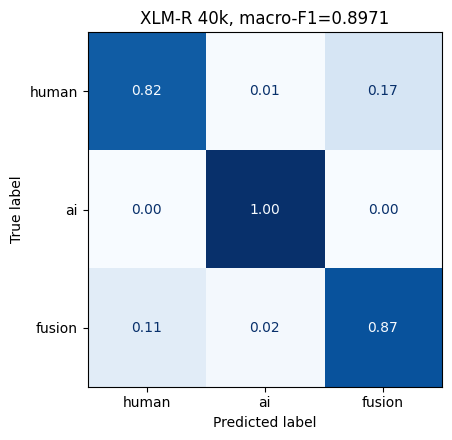

In [7]:
pred_out = trainer.predict(val_ds)
y_pred   = np.argmax(pred_out.predictions, axis=-1)
y_true   = val["label_id"].values

macro = f1_score(y_true, y_pred, average="macro")
per   = f1_score(y_true, y_pred, average=None, labels=list(range(len(LABELS))))

print(f"=== Encoder XLM-R (40k) ===")
print(f"macro-F1 = {macro:.4f}")
for i, l in enumerate(LABELS):
    print(f"  {l:8s} F1 = {per[i]:.4f}")

print("\n" + classification_report(y_true, y_pred, labels=list(range(len(LABELS))),
                                    target_names=LABELS, digits=4))

# Confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(LABELS))))
cm_n = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm_n, display_labels=LABELS).plot(
    ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
ax.set_title(f"XLM-R 40k, macro-F1={macro:.4f}")
plt.tight_layout()
plt.savefig(f"{BASE}/encoder_xlmr_40k_confusion.png", dpi=150)
plt.show()

## 7. Save fine-tuned weights — **do not skip**

Saves model + tokenizer to `/kaggle/working/encoder_xlmr_40k/`. After this cell runs, you **must** do:

**Save Version → Save & Run All (Commit) → check "Save Output"**

Then the weights persist as a Kaggle output. To reuse them in another notebook, add this notebook's output as a dataset, or download the folder from the notebook's Output tab[citation:24].

In [8]:
SAVE_DIR = f"{BASE}/encoder_xlmr_40k"
os.makedirs(SAVE_DIR, exist_ok=True)

trainer.model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

# Save label mapping explicitly so inference is unambiguous
with open(f"{SAVE_DIR}/label_map.json", "w") as f:
    json.dump({"label2id": LABEL2ID, "id2label": ID2LABEL}, f, indent=2)

# Save eval metrics for the report
metrics = {
    "macro_f1": float(macro),
    "f1_human": float(per[0]),
    "f1_ai": float(per[1]),
    "f1_fusion": float(per[2]),
    "model": MODEL_NAME,
    "max_len": MAX_LEN,
    "truncation": "head+tail (256+256)",
    "train_rows": int(len(sub40)),
    "val_rows": int(len(val)),
    "class_weights": dict(zip(LABELS, [float(x) for x in cw])),
}
with open(f"{BASE}/encoder_xlmr_40k_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved to:", SAVE_DIR)
for fn in sorted(os.listdir(SAVE_DIR)):
    p = os.path.join(SAVE_DIR, fn)
    print(f"  {fn}  ({os.path.getsize(p)/1e6:.1f} MB)" if os.path.isfile(p) else f"  {fn}/")
print("\nMetrics:", json.dumps(metrics, indent=2))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: /kaggle/working/encoder_xlmr_40k
  checkpoint-2500/
  config.json  (0.0 MB)
  label_map.json  (0.0 MB)
  model.safetensors  (1112.2 MB)
  tokenizer.json  (17.1 MB)
  tokenizer_config.json  (0.0 MB)

Metrics: {
  "macro_f1": 0.8970877341322906,
  "f1_human": 0.8371857258718572,
  "f1_ai": 0.9891094755710057,
  "f1_fusion": 0.8649680009540088,
  "model": "xlm-roberta-base",
  "max_len": 512,
  "truncation": "head+tail (256+256)",
  "train_rows": 40000,
  "val_rows": 40853,
  "class_weights": {
    "human": 1.3604054008094413,
    "ai": 0.7445046252349843,
    "fusion": 1.0848928668294007
  }
}


In [9]:
# Sanity: reload from disk and run one prediction — proves weights are usable
from transformers import AutoModelForSequenceClassification, AutoTokenizer

reload_tok = AutoTokenizer.from_pretrained(SAVE_DIR)
reload_mod = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR).to("cuda").eval()

test_enc = encode_headtail(val["text"].iloc[0], reload_tok, MAX_LEN)
with torch.no_grad():
    out = reload_mod(torch.tensor([test_enc["input_ids"]]).to("cuda"),
                     attention_mask=torch.tensor([test_enc["attention_mask"]]).to("cuda"))
pred_id = out.logits.argmax(-1).item()
print("Reload OK | sample pred:", ID2LABEL[pred_id], "| true:", val["label"].iloc[0])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Reload OK | sample pred: human | true: human
